In [24]:
# Install required packages
!pip install pandas numpy matplotlib seaborn scikit-learn tensorflow nltk wordcloud

In [25]:
#  Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import tensorflow as tf
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D
from tensorflow.keras.callbacks import EarlyStopping
import re
import warnings
warnings.filterwarnings('ignore')

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [26]:
# Load and explore the dataset

file_path = '/content/10k-Dataset.csv'
df = pd.read_csv(file_path)

# Drop the Unnamed: 0 column as it's not needed
df.drop('Unnamed: 0', axis=1, inplace=True)

# Display basic info
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (10000, 2)

First 5 rows:
                                                text     Emotion
0  i do feel like i am alot more outgoing then i ...     neutral
1  i go back and face the home in that ruined sta...     neutral
2          i feel the amount allocated is inadequate     neutral
3  im feeling very mellow and affectionate right now        love
4  i feel their anticipation on the update and i ...  enthusiasm

Missing values:
text       0
Emotion    0
dtype: int64


In [27]:
# Display emotion distribution
print("\nEmotion distribution:")
print(df['Emotion'].value_counts())


Emotion distribution:
Emotion
neutral       8005
love           472
happiness      332
sadness        213
relief         201
hate           186
anger          152
fun            126
enthusiasm     116
empty           73
surprise        68
worry           55
boredom          1
Name: count, dtype: int64


In [29]:
# Text preprocessing
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    # Remove special characters and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text, re.I|re.A)
    # Tokenize
    tokens = text.split()
    # Remove stopwords and lemmatize
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    # Join tokens back to string
    return ' '.join(tokens)

# Apply preprocessing
df['clean_text'] = df['text'].apply(preprocess_text)



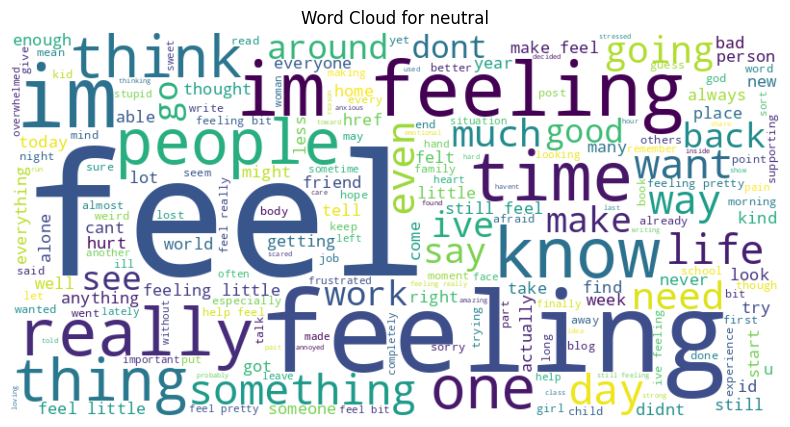

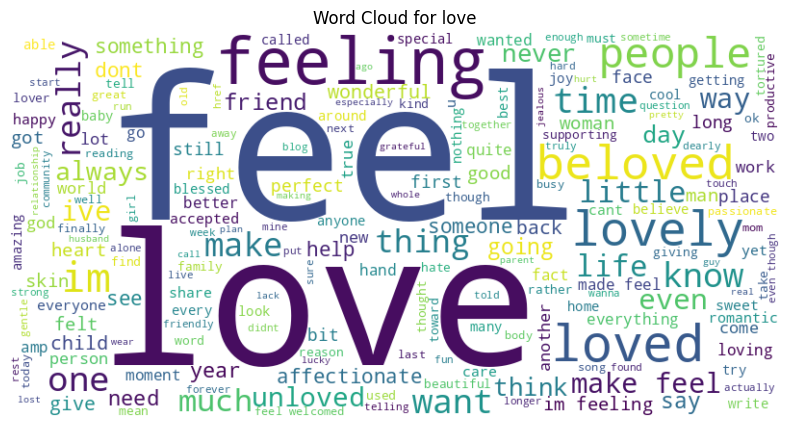

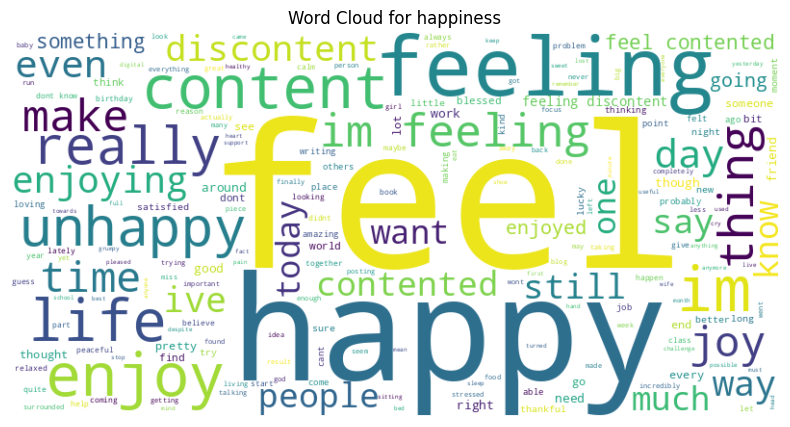

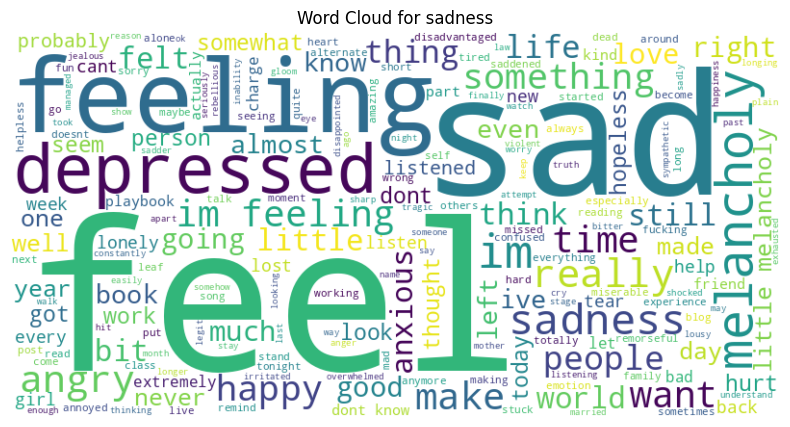

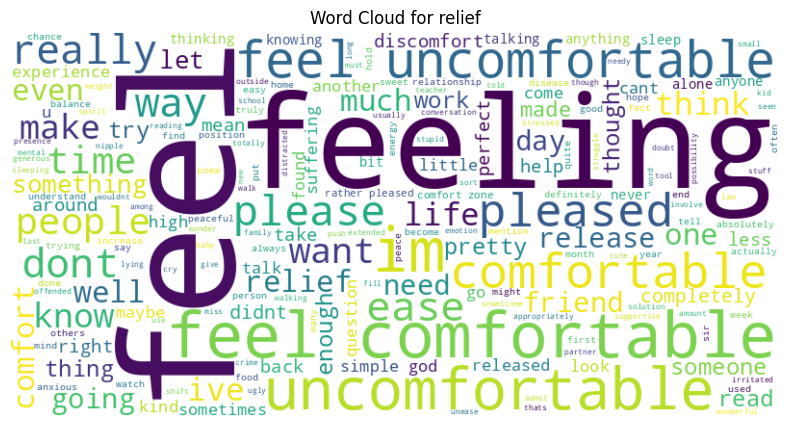

In [30]:
# Word cloud visualization for each emotion
def plot_wordcloud(emotion):
    text = ' '.join(df[df['Emotion'] == emotion]['clean_text'])
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(f'Word Cloud for {emotion}')
    plt.axis('off')
    plt.show()

# Plot word clouds for top emotions
for emotion in df['Emotion'].value_counts().index[:5]:
    plot_wordcloud(emotion)

In [31]:
# Prepare data for modeling - Handling class imbalance

# First, remove the 'boredom' class which only has 1 sample
df = df[df['Emotion'] != 'boredom']

# Verify new distribution
print("Updated Emotion distribution:")
print(df['Emotion'].value_counts())

# Simple approach - proceed without balancing (will have imbalanced classes)
# Encode labels
label_encoder = LabelEncoder()
df['encoded_emotion'] = label_encoder.fit_transform(df['Emotion'])

# Split data into train and test (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], df['encoded_emotion'],
    test_size=0.3,
    random_state=42,
    stratify=df['encoded_emotion']  # Now safe to use since all classes have ≥2 samples
)

# Tokenize text
max_words = 10000  # We'll use the top 10,000 words
max_len = 100      # Maximum length of sequences

tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train)

# Convert text to sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Pad sequences to ensure uniform length
X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len)

# Get number of classes
num_classes = len(label_encoder.classes_)

Updated Emotion distribution:
Emotion
neutral       8005
love           472
happiness      332
sadness        213
relief         201
hate           186
anger          152
fun            126
enthusiasm     116
empty           73
surprise        68
worry           55
Name: count, dtype: int64


In [32]:
#  Build and display LSTM model properly

embedding_dim = 128  # Dimension of word embeddings

# Build the model
model = Sequential()
model.add(Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=max_len))
model.add(SpatialDropout1D(0.2))
model.add(LSTM(128, dropout=0.2, recurrent_dropout=0.2))
model.add(Dense(num_classes, activation='softmax'))

# Compile the model
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Force model building by passing a sample input

dummy_input = tf.ones((1, max_len))
model(dummy_input)

# Now display the proper summary
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (1, 100, 128)          │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_2             │ (1, 100, 128)          │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (1, 128)               │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (1, 12)                │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,413,132 (5.39 MB)

 Trainable params: 1,413,132 (5.39 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
#  Train the model
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    X_train_pad, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_test_pad, y_test),
    callbacks=[early_stopping],
    verbose=1)

Epoch 1/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 55s 414ms/step - accuracy: 0.7730 - loss: 1.2223 - val_accuracy: 0.8007 - val_loss: 0.9200
Epoch 2/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 86s 451ms/step - accuracy: 0.8099 - loss: 0.8331 - val_accuracy: 0.8353 - val_loss: 0.6595
Epoch 3/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 84s 474ms/step - accuracy: 0.8538 - loss: 0.5124 - val_accuracy: 0.8697 - val_loss: 0.4785
Epoch 4/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 50s 457ms/step - accuracy: 0.8953 - loss: 0.3539 - val_accuracy: 0.9013 - val_loss: 0.3962
Epoch 5/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 85s 482ms/step - accuracy: 0.9275 - loss: 0.2680 - val_accuracy: 0.9330 - val_loss: 0.2771
Epoch 6/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 80s 461ms/step - accuracy: 0.9627 - loss: 0.1494 - val_accuracy: 0.9530 - val_loss: 0.2306
Epoch 7/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 49s 444ms/step - accuracy: 0.9779 - loss: 0.0892 - val_accuracy: 0.9650 - val_loss: 0.1947
Epoch 8/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 87s 488ms/step - accuracy: 0.9834 - loss: 0

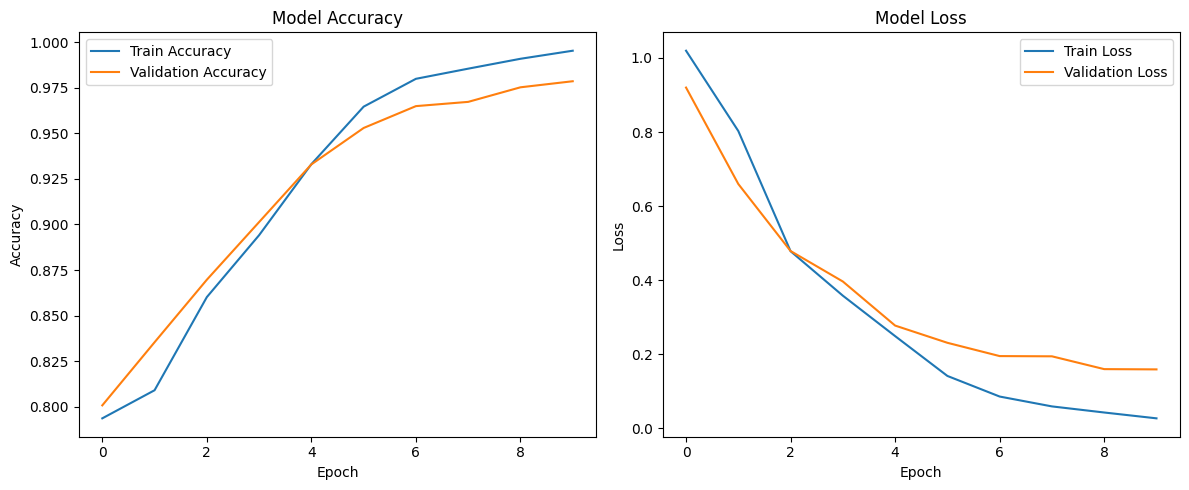

In [34]:
#   Plot training history
plt.figure(figsize=(12, 5))

# Plot accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 64ms/step
Classification Report:
              precision    recall  f1-score   support

       anger       0.85      0.89      0.87        45
       empty       1.00      0.73      0.84        22
  enthusiasm       0.97      0.94      0.96        35
         fun       0.86      0.82      0.84        38
   happiness       0.94      0.99      0.97       100
        hate       0.98      0.91      0.94        56
        love       0.98      0.97      0.98       142
     neutral       0.99      1.00      0.99      2402
      relief       0.93      0.72      0.81        60
     sadness       0.98      0.94      0.96        64
    surprise       0.95      1.00      0.98        20
       worry       0.65      0.69      0.67        16

    accuracy                           0.98      3000
   macro avg       0.92      0.88      0.90      3000
weighted avg       0.98      0.98      0.98      3000



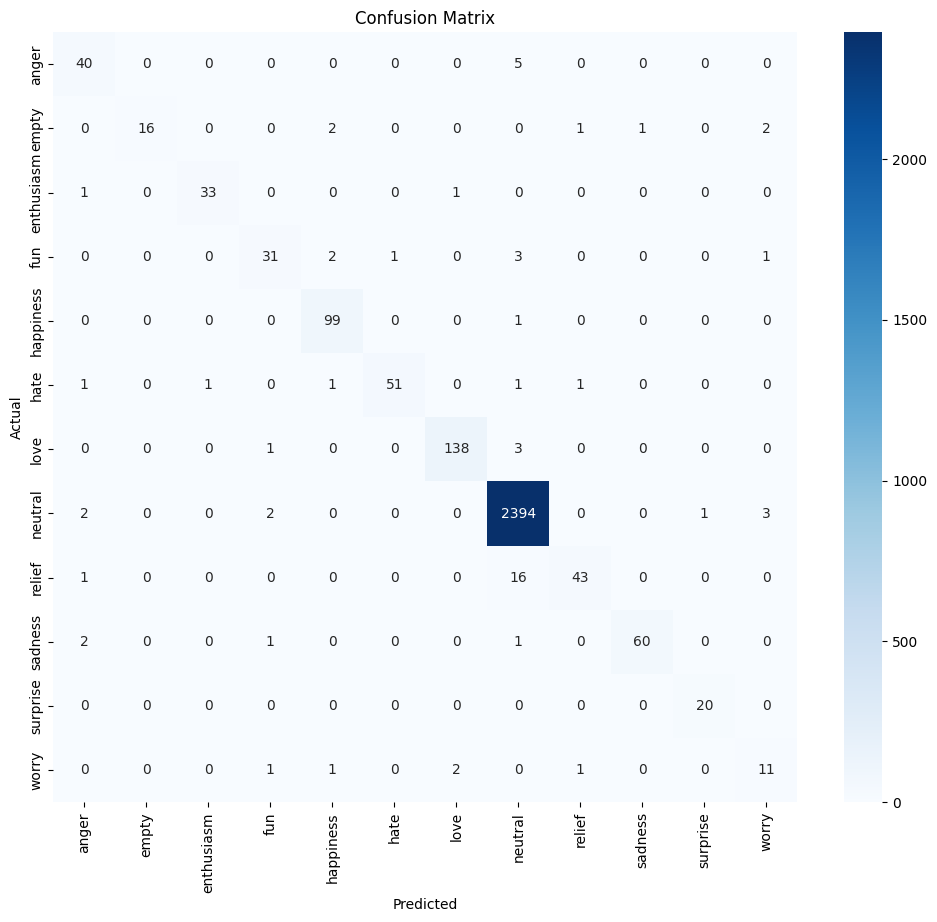


Accuracy: 0.9787
F1-Score: 0.9781
Precision: 0.9786
Recall: 0.9787


In [35]:
#  Evaluate the model
# Predict on test set
y_pred = model.predict(X_test_pad)
y_pred_classes = np.argmax(y_pred, axis=1)

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred_classes, target_names=label_encoder.classes_))

# Confusion matrix
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_test, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Calculate and display metrics
accuracy = accuracy_score(y_test, y_pred_classes)
f1 = f1_score(y_test, y_pred_classes, average='weighted')
precision = precision_score(y_test, y_pred_classes, average='weighted')
recall = recall_score(y_test, y_pred_classes, average='weighted')

print(f"\nAccuracy: {accuracy:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

In [36]:
# Function to predict emotion with optional details
def predict_emotion(text, show_details=False):
    # Preprocess the input text
    cleaned = preprocess_text(text)

    # Tokenize and pad
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=max_len)

    # Make prediction
    prediction = model.predict(padded, verbose=0)
    pred_index = np.argmax(prediction)
    emotion = label_encoder.inverse_transform([pred_index])[0]
    confidence = float(np.max(prediction))

    if show_details:
        print("\n--- Prediction Details ---")
        print(f"Original Text     : {text}")
        print(f"Cleaned Text      : {cleaned}")
        print(f"Predicted Emotion : {emotion}")
        print(f"Confidence Score  : {confidence:.2%}")
        print("\nEmotion Probabilities:")
        for i, (em, prob) in enumerate(zip(label_encoder.classes_, prediction[0])):
            print(f"  {i+1}. {em:12} => {prob:.4f}")
        print("--------------------------\n")

    return emotion, confidence


# Command-line interface for user interaction
def emotion_recognition_cli():
    print("=" * 50)
    print("      Text-Based Emotion Recognition System")
    print("=" * 50)
    print("Type 'quit' to exit.\n")

    while True:
        text = input("Enter your text: ").strip()
        if text.lower() == 'quit':
            print("\nExiting Emotion Recognition. Goodbye!")
            break

        emotion, confidence = predict_emotion(text)
        print(f"\n>> Predicted Emotion: {emotion}")
        print(f">> Confidence Score : {confidence:.2%}\n")

# Run the CLI
emotion_recognition_cli()


      Text-Based Emotion Recognition System
Type 'quit' to exit.

Enter your text: i was just feeling kind of sad and lonely and in a weak moment i went to the store and bought a bag of chips and some dip

>> Predicted Emotion: sadness
>> Confidence Score : 99.72%

Enter your text: ive even talked about all those lovely topics like the birds amp bees using protection and childbirth during these car rides without feeling too embarrassed

>> Predicted Emotion: love
>> Confidence Score : 99.61%

Enter your text: i feel so distressed that my true love is a capulet

>> Predicted Emotion: love
>> Confidence Score : 98.88%

Enter your text: exit

>> Predicted Emotion: neutral
>> Confidence Score : 99.97%

Enter your text: exit()

>> Predicted Emotion: neutral
>> Confidence Score : 99.97%

Enter your text: quit

Exiting Emotion Recognition. Goodbye!
